# Transcript Intelligence — technical notebook

**Dataset:** 100 call recordings from *Aegis Cloud Security* (fictional B2B security SaaS: Detect, Protect, Comply, Identity), 3 Feb – 28 Apr 2026.
Each call ships 6 JSON files: meeting info, transcript sentences (with speaker + sentence sentiment), speaker timeline, join/leave events and a vendor summary (summary, topics, call-level sentiment, key moments).

**Pipeline**

| Stage | What | Method | Why this method |
|---|---|---|---|
| 1 | Call type (support / external / internal) | Rules on metadata | Structural fact about who's on the call — rules are free, exact and auditable |
| 2 | Topic category + judgement fields | LLM (Claude) with a fixed taxonomy, cached; keyword fallback for uncached calls | Calls are multi-intent; churn risk, root cause, "known bug?" need reading comprehension |
| 2b | Taxonomy discovery + sanity check | TF-IDF + KMeans, keyword baseline | Shows where the categories came from and what the LLM adds over cheap methods |
| 2c | Entities: product modules, competitors | Regex | Closed vocabularies — no model needed |
| 3 | Sentiment | Decompose shipped sentence labels by speaker side & call position | A call score hides *whose* sentiment and *when* |
| 4 | Insights | Joins across calls, accounts and time | The value is in connecting calls, not scoring them one by one |

**Data decisions:** I did not generate synthetic data. All three call types are present and balanced (40 external / 30 support / 30 internal), and 24 of 32 customer accounts appear in more than one call, which is enough to show cross-call patterns. Adding synthetic calls would make the trends look stronger without making them more true. The second zip in the submission is an exact 6-call subset of the first (checked file by file), so it was deduplicated.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="Converting to PeriodArray")
# Repo root = the folder holding src/ti, wherever Jupyter was started from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ti").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from ti.load import load_dataset
from ti.call_type import add_call_type
from ti.taxonomy import CATEGORIES
from ti import discovery, insights, sentiment, viz
from ti.pipeline import run

## 1 · Load & call-type classification

Every speaker name maps to an email in `allEmails` (311/311), so each sentence is tagged **aegis** or **customer**. That one join is what makes the customer-voice sentiment in section 3 possible.

In [2]:
meetings, utts = load_dataset(ROOT / "data" / "raw")
print(f"{len(meetings)} calls, {len(utts):,} sentences, {meetings.duration_min.sum()/60:.1f} hours of audio")
print("speaker->email match rate:", utts.email.notna().mean())
meetings = add_call_type(meetings)
meetings.call_type.value_counts()

100 calls, 4,313 sentences, 50.5 hours of audio
speaker->email match rate: 1.0


,count
call_type,
external,40
support,30
internal,30


In [3]:
# Rule check: one example title per call type
meetings.groupby("call_type").title.apply(lambda s: list(s.head(3)))

,title
call_type,
external,"[Aegis / Coastal Living Co - Onboarding Kickoff, Aegis / Blackridge Investments - Renewal Discussion, Aegis / Brightpath Commerce - Detect Module Deployment]"
internal,"[Detect Team - Sprint Planning, Product Sync - Identity Roadmap, Comply v2 - Design Review]"
support,"[Support Case #3286 - Vanta Health Systems API Integration Error, Support Case #9279 - Summit Trust Billing Inquiry, Support Case #3615 - Nimbus Platform Custom Report Request]"


## 2 · Topic categorisation

### 2a. Discovery — what groupings exist?
Before writing a taxonomy I clustered the calls (TF-IDF on title + summary + vendor topic tags, KMeans, k chosen by silhouette) and read each cluster's top terms.

In [4]:
calls, utts = run()          # full pipeline (stages 1–3), cached LLM labels
labels, k, scores, top_terms = discovery.cluster(calls)
print("best k =", k, "| silhouette by k:", {kk: round(v, 3) for kk, v in scores.items()})
pd.DataFrame({"size": pd.Series(labels).value_counts().sort_index(),
              "top terms": pd.Series({c: ", ".join(t) for c, t in top_terms.items()})})

best k = 11 | silhouette by k: {6: np.float64(0.037), 7: np.float64(0.035), 8: np.float64(0.038), 9: np.float64(0.035), 10: np.float64(0.037), 11: np.float64(0.045), 12: np.float64(0.045)}


,size,top terms
0,9,"backup, performance, issue, support, yuki, connector, identified, case"
1,14,"framework, multi framework, soc, audit, multi, evidence, comply, pci dss"
2,11,"launch, v2, comply v2, comply, april, qa, reporting, v2 launch"
3,7,"billing, overage, dispute, invoice, discrepancy, summit trust, summit, case"
4,7,"granular, feature, roadmap, paula, identity, ridgeline, renewal, session"
5,17,"failure, outage, incident, event, monitoring, pipeline, detect, hours"
6,5,"nova, retail, saml, stephanie, nova retail, support, affecting, sso"
7,8,"mfa, identity, access, deployment, access management, session, victor, roadmap"
8,14,"renewal, outage, competitive, hour, contract, pricing, concerns, sla"
9,5,"sprint, sprint planning, retrospective, planning, deduplication, pipeline, alert deduplication, sprint retrospective"


**What the clusters say.** The groups are easy to recognise: outage, billing, Comply / multi-framework, Comply v2 launch, renewal + competitive, sprint rituals, Identity, onboarding. Those became the base of the taxonomy. But the **silhouette is very low (~0.04)**. Every call shares the same vocabulary (Detect, outage, compliance), so the clusters overlap heavily. Some clusters also form around a *customer name* ("nova retail", "summit trust", "yuki") rather than an intent. On its own, clustering is good for finding themes and poor at assigning calls to them.

### 2b. Taxonomy
Ten categories, each defined by **the decision it supports and who owns it**. One primary label per call, plus up to two secondary labels (multi-label).

In [5]:
pd.DataFrame(CATEGORIES).T[["name", "owner", "definition"]]

,name,owner,definition
OUTAGE,Outage & Incident Response,"Eng leads, Support leaders","Service outage handling: war rooms, customer impact, RCA, post-mortems, reliability follow-up."
DEFECT,Product Defects & Tech Issues,"Support leaders, Eng leads","A specific bug, regression, misconfiguration or performance problem being troubleshot."
BILLING,Billing & Usage Disputes,"Finance, Account managers","Invoices, overages, seat counts, proration, credits."
FEATURE,Feature Requests & Product Gaps,Product managers,Customer asks for capability that does not exist or is insufficient.
RENEWAL,Renewals & Account Health,"Sales managers, CSMs","Renewal, QBR, contract, pricing, expansion or retention conversation."
ONBOARD,Onboarding & Deployment,CS / Professional services,"Kickoffs, deployment planning, tuning after go-live."
COMPLY,Compliance & Audit Readiness,"Product (Comply), Sales","Audit prep (SOC 2, HIPAA, PCI, ISO), Comply demos, internal certification work."
PLANNING,Eng Planning & Roadmap,"Eng leads, Product","Sprint planning, retros, standups, roadmap and quarterly planning, all-hands."
LAUNCH,Product Launch (Comply v2),"Product, Eng, Marketing","Design review, launch readiness, GA plan, adoption review for a launch."
GTM,Competitive & GTM Strategy,"Sales leadership, Product marketing","Competitive landscape, win/loss, competitive response."


### 2c. LLM labelling
Prompt: `prompts/classify_call.md`. The model reads the summary and the full transcript and returns JSON: `primary`, `secondary`, `churn_risk`, `outage_related`, `comm_gap`, `support_delay`, `known_issue`, `remediation_side_effect`, `root_cause`, `resolution`, `rationale`.
Results are cached in `labels/llm_labels.json`, so this notebook runs offline and gives the same numbers every time.

> **Provenance, stated plainly:** the cached labels were produced by Claude in an interactive session, applying this prompt's taxonomy and field definitions to each call's summary and transcript excerpts. They were not produced by the API code path. `python refresh_labels.py --all` (needs `pip install anthropic` and an API key) regenerates all 100 labels through the API from the full transcripts, with the output constrained to the label schema. Every cached label is also schema-validated on load.
>
> **New calls:** a call with no cached label is never dropped. With `--use-api` it is labelled by Claude and added to the cache; otherwise it gets the keyword label and `label_source = "keyword"`, with the judgement fields marked `unknown` (see 2e).

In [6]:
calls[["start", "call_type", "title", "category", "secondary", "churn_risk", "rationale"]].sample(8, random_state=1)

,start,call_type,title,category,secondary,churn_risk,rationale
80,2026-04-16 13:00:00+00:00,external,Aegis / Pinnacle Insurance - Detect Roadmap Review,Feature Requests & Product Gaps,"[OUTAGE, COMPLY]",low,Detect roadmap asks incl. pipeline health visibility.
84,2026-04-19 15:15:00+00:00,external,Aegis / Coastal Living Co - Protect Module Expansion,Onboarding & Deployment,[RENEWAL],none,Protect module expansion planning.
33,2026-03-09 16:45:00+00:00,external,Aegis / Keystone Health - Renewal Planning,Renewals & Account Health,[COMPLY],none,Three-year renewal lock agreed.
81,2026-04-17 09:45:00+00:00,external,Aegis / Axiom Labs - Multi-Year Renewal,Renewals & Account Health,[],low,Multi-year renewal proposal.
93,2026-04-25 14:45:00+00:00,external,Aegis / Frostbyte AI - Product Feedback,Feature Requests & Product Gaps,[],low,Identity role hierarchy and session policy gaps.
17,2026-02-22 13:15:00+00:00,external,Aegis / Redwood Clinical - Product Feedback Session,Feature Requests & Product Gaps,[COMPLY],medium,Four prioritised Comply reporting gaps; hints at VaultEdge evaluation.
36,2026-03-11 11:00:00+00:00,internal,Detect Outage - Escalation Bridge,Outage & Incident Response,[],none,Internal escalation bridge during outage.
82,2026-04-17 17:15:00+00:00,internal,Weekly Engineering Standup,Eng Planning & Roadmap,"[OUTAGE, LAUNCH]",none,Standup on post-mortem items and Comply v2 bug.


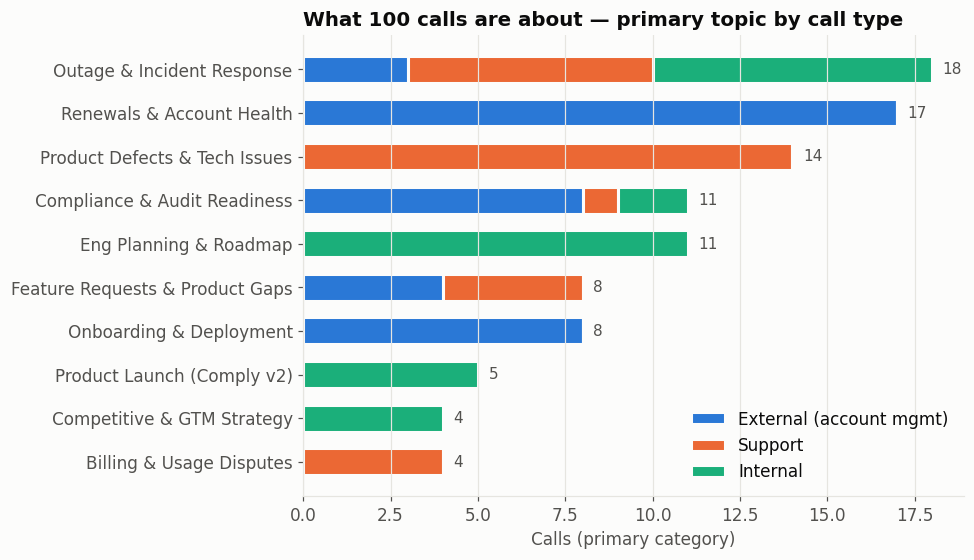

In [7]:
fig = viz.categories_by_type(calls); plt.show()

### Examples per category

In [8]:
g = calls.sort_values("start").groupby("category")
ex = pd.DataFrame({"n": g.size(), "examples": g.title.agg(lambda t: " | ".join(t.head(3)))})
ex.sort_values("n", ascending=False)

,n,examples
category,,
Outage & Incident Response,18,URGENT: Cobalt Software - Aegis Detect Dashboard Down | INCIDENT: Detect Pipeline Failure - War Room | Detect Outage - Escalation Bridge
Renewals & Account Health,17,Aegis / Blackridge Investments - Renewal Discussion | Aegis / Crestline Wealth - Account Review | Aegis / Atlas Precision - Contract Discussion
Product Defects & Tech Issues,14,Support Case #3286 - Vanta Health Systems API Integration Error | Support Case #6635 - Nova Retail Group SSO Login Failures | Support Case #1750 - Vanta Health Systems SIEM Connector Issue
Compliance & Audit Readiness,11,Aegis / Bridgeport Health - Compliance Review | SOC 2 Audit Preparation - Internal | Aegis / Maplewood Goods - SOC 2 Prep Review
Eng Planning & Roadmap,11,Detect Team - Sprint Planning | Product Sync - Identity Roadmap | Weekly Engineering Standup
Feature Requests & Product Gaps,8,Support Case #3615 - Nimbus Platform Custom Report Request | Aegis / Redwood Clinical - Product Feedback Session | Aegis / Ridgeline Logistics - Identity Roadmap Discussion
Onboarding & Deployment,8,Aegis / Coastal Living Co - Onboarding Kickoff | Aegis / Brightpath Commerce - Detect Module Deployment | Aegis / Frostbyte AI - Identity Module Setup
Product Launch (Comply v2),5,Comply v2 - Design Review | Comply v2 - Launch Readiness Review | Comply v2 - GA Deployment Plan
Competitive & GTM Strategy,4,Competitive Landscape Review | Competitive Threat Assessment - Post Outage | Competitive Response Strategy


### 2d. How much does the LLM add? (agreement check)
A keyword scorer over title + summary (`taxonomy.keyword_classify`) agrees with the LLM on 80% of calls, and KMeans reaches an ARI of 0.38. The useful part is **where they disagree**:

In [9]:
print(f"keyword vs LLM agreement: {(calls.kw_primary == calls.primary).mean():.0%}")
print(f"KMeans vs LLM ARI: {discovery.agreement(labels, calls.primary):.2f}")
dis = calls[calls.kw_primary != calls.primary][["title", "kw_primary", "primary", "secondary"]]
dis

keyword vs LLM agreement: 80%
KMeans vs LLM ARI: 0.38


,title,kw_primary,primary,secondary
7,Aegis / Brightpath Commerce - Detect Module Deployment,OUTAGE,ONBOARD,[]
8,Comply v2 - Design Review,COMPLY,LAUNCH,[PLANNING]
20,Aegis / Atlas Precision - Contract Discussion,BILLING,RENEWAL,[BILLING]
33,Aegis / Keystone Health - Renewal Planning,COMPLY,RENEWAL,[COMPLY]
44,Support Case #5889 - Ridgeline Logistics Detect Latency Issues,DEFECT,OUTAGE,[]
45,ESCALATION: Northstar Pharma - Detect Outage Impact on Compliance,COMPLY,OUTAGE,[COMPLY]
52,Competitive Threat Assessment - Post Outage,OUTAGE,GTM,[OUTAGE]
55,Comply v2 - Launch Readiness Review,COMPLY,LAUNCH,[]
58,Aegis / Summit Trust - Platform Concerns Discussion,OUTAGE,RENEWAL,"[DEFECT, OUTAGE]"
72,Competitive Response Strategy,COMPLY,GTM,[OUTAGE]


**Reading the disagreements.** 18 of the 20 come from the keyword scorer picking the loudest topic word, either *outage* (10) or *compliance* (8), over the purpose of the call. The biggest single group is **renewal calls labelled OUTAGE** (4). A sales manager filtering for renewals would miss exactly those at-risk accounts under keyword rules. That is the case for an LLM: it labels a call by its purpose, not by its most frequent words.

**Production design:** rules for call type → LLM for topic and judgement fields → keyword scorer kept as an offline fallback and a drift alarm (if agreement drops sharply, the taxonomy or prompt needs revisiting).

### 2e. Scoring a new call
`data/sample/` holds one call that is not in the label cache: a support case about an alert storm after a Detect agent upgrade, where the customer also mentions a June renewal and a SentinelShield quote. Without an API call it is scored with the keyword fallback:

In [10]:
new_calls, new_utts = run(ROOT / "data" / "sample")
new_calls[["title", "call_type", "label_source", "category", "modules", "competitors",
           "sentiment_score", "customer_net", "aegis_net", "open_net", "close_net", "recovery"]].T

,0
title,Support Case #4421 - Harbor Lane Foods Detect Alert Storm After Agent Upgrade
call_type,support
label_source,keyword
category,Product Defects & Tech Issues
modules,[Detect]
competitors,[SentinelShield]
sentiment_score,2.7
customer_net,-0.25
aegis_net,0.333333
open_net,-1.0


Everything structural is right: support call, Detect module, SentinelShield mention, and the customer opening at −1.0 and closing at +1.0 once the baseline was restored live. The keyword topic is DEFECT, which is correct. What the fallback cannot give is the judgement layer: an LLM label (`python run_pipeline.py --data data/sample --use-api`) would add RENEWAL as secondary, churn risk *high*, a known issue and a communication gap. Those are the fields that make this call worth escalating to the account owner.

## 3 · Sentiment

### 3a. Can we trust the shipped labels?
The vendor's call-level score (1–5) and our aggregate of sentence labels agree closely (Spearman ρ ≈ 0.93), so the rest of this section builds on the sentence labels.

In [11]:
pd.Series(sentiment.validate_against_vendor(calls)).astype(float).round(4)

,0
rho_all_vs_vendor,0.933
p,0.000
rho_customer_vs_vendor,0.941
p_customer,0.000


In [12]:
calls.groupby("call_type")[["sentiment_score", "customer_net", "aegis_net", "empathy_gap", "recovery", "customer_talk_share"]].mean().round(2)

,sentiment_score,customer_net,aegis_net,empathy_gap,recovery,customer_talk_share
call_type,,,,,,
external,3.85,0.20,0.47,0.27,0.36,0.43
internal,3.42,NaN,0.04,NaN,NaN,0.00
support,2.83,-0.37,0.01,0.38,0.23,0.42


### 3b. Trend over time — four phases set by the two events in the data

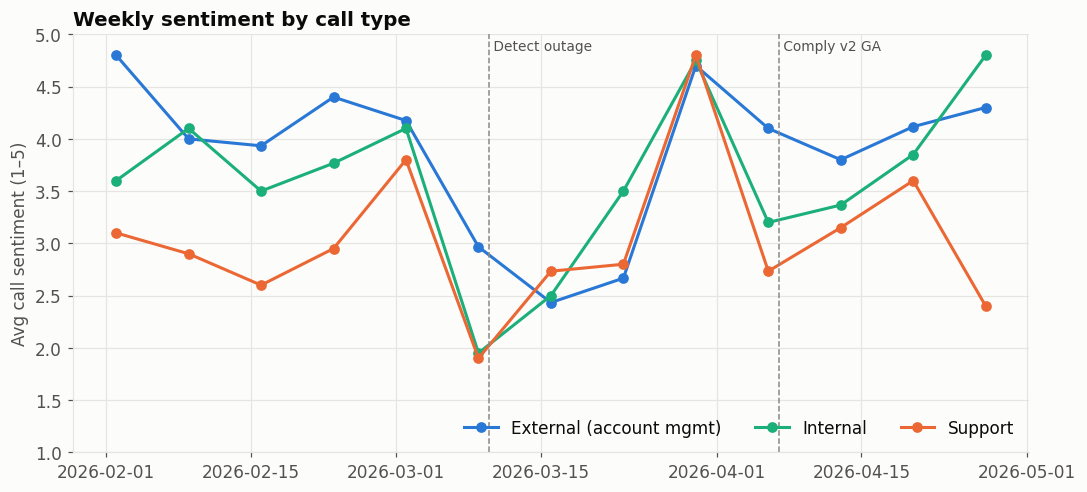

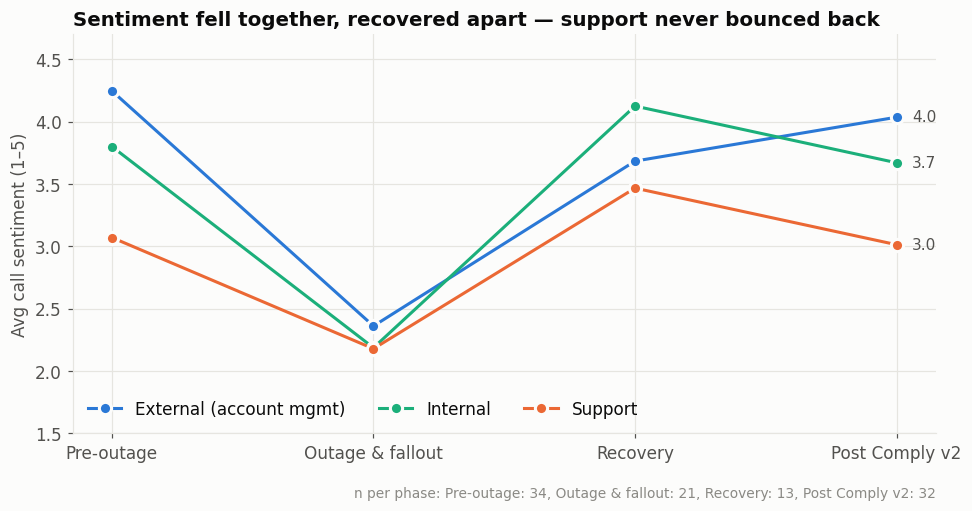

mean                      size                 
call_type          external internal support external internal support
phase                                                                 
1 Pre-outage           4.25     3.80    3.07       15        9      10
2 Outage & fallout     2.36     2.19    2.18        5        7       9
3 Recovery             3.68     4.12    3.47        6        4       3
4 Post Comply v2       4.04     3.67    3.01       14       10       8

In [13]:
fig = viz.weekly_trend(calls); plt.show()
fig = viz.sentiment_by_phase(calls); plt.show()
calls.pivot_table(index="phase", columns="call_type", values="sentiment_score", aggfunc=["mean", "size"]).round(2)

**What it means**
* All three call types hit their low in the same two weeks (10–23 Mar). The outage drives sentiment everywhere: internal morale, customer calls and support.
* **External calls recovered to 4.0, close to their pre-outage 4.25. Support did not (3.0 now vs 3.1 before; the post-launch support average sits below the recovery-phase level).** Of the 8 support calls since Comply v2 launched, 7 have an Aegis-side root cause and 5 trace back to the outage remediation itself (section 4c). Leadership looking at renewal calls would conclude "we're through it"; the support queue says otherwise.

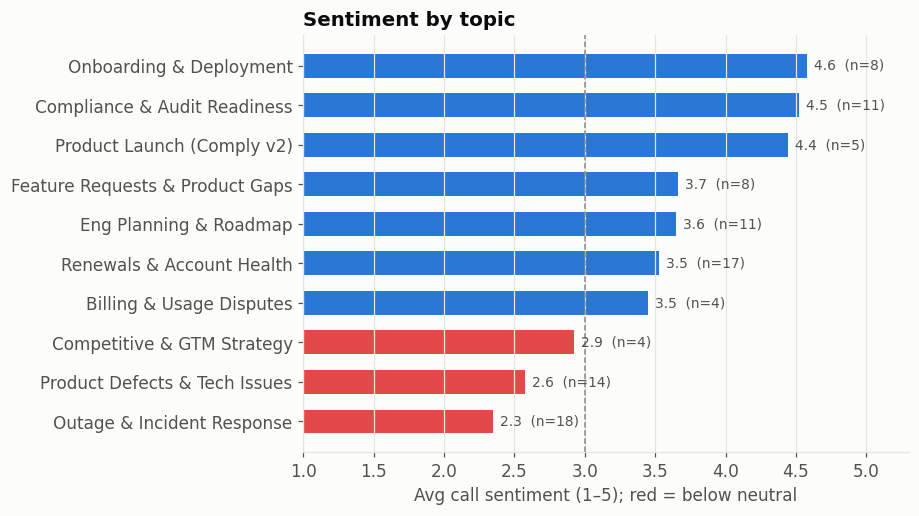

In [14]:
fig = viz.sentiment_by_category(calls); plt.show()

### 3c. Whose sentiment? The empathy gap

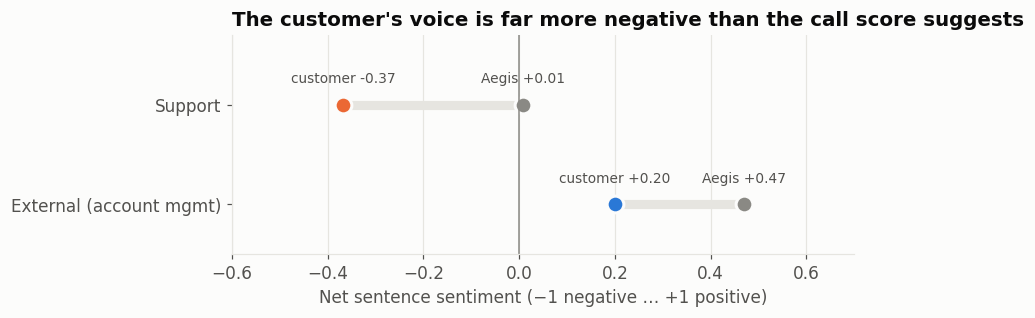

In [15]:
fig = viz.empathy_gap(calls); plt.show()

On support calls, customers' sentences net out to **−0.37** while Aegis agents sit at **+0.01**. A call-level score blends the two, so an angry customer talking to a calm agent reads as "mixed". **Recommendation:** report customer-side sentiment as the headline metric for support and CS; keep the blended score for internal calls only.

### 3d. Within-call trajectory — do calls de-escalate?

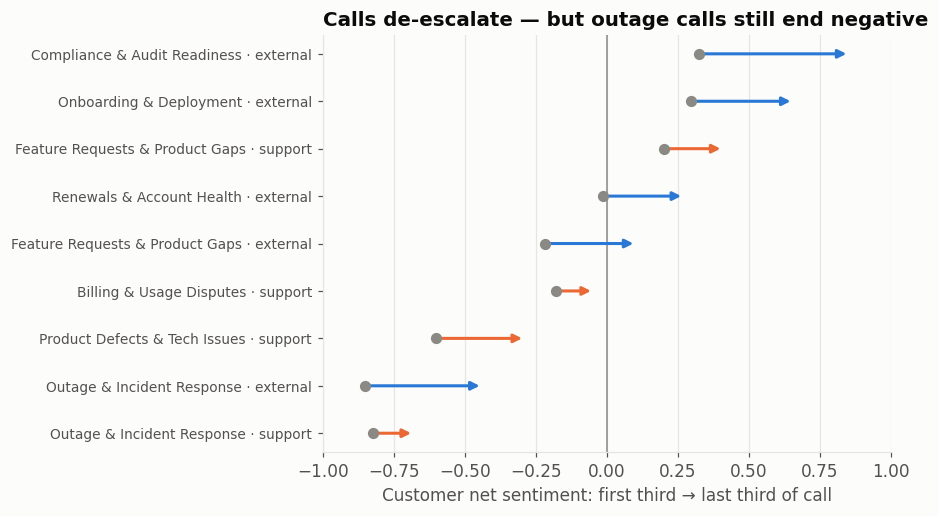

,recovery
call_type,
external,82% of calls end better than they start
support,80% of calls end better than they start


In [16]:
fig = viz.within_call_recovery(calls); plt.show()
calls[calls.call_type != "internal"].groupby("call_type").recovery.apply(lambda s: f"{(s > 0).mean():.0%} of calls end better than they start")

About 80% of customer calls end more positive than they start, so agents are good at de-escalating *inside* a call. The exception is outage calls on the support line, which open at −0.82 and close at −0.68. Agents cannot talk their way out of a platform failure, which points to a product and communications fix rather than a support training fix.

## 4 · Beyond topic & sentiment

### 4a. Early warning: the outage was visible in internal calls 32 days in advance

In [17]:
ew = insights.early_warning_signals(utts, calls)
ew.groupby(["start", "title"]).agg(lead_days=("lead_days", "first"), quotes=("text", "size"), example=("text", "first"))

,,lead_days,quotes,example
start,title,,,
2026-02-05 14:15:00+00:00,Detect Team - Sprint Planning,32,3,"Yeah the pipeline latency investigation has been sitting in my queue and honestly the more I dig into it the more I think we have a deeper architectural issue with the event ingestion layer. Like it's not just latency, there are some single point of failure concerns I want to flag."
2026-02-16 10:00:00+00:00,Weekly Engineering Standup,21,2,"Not right now. I might need some time with Mike later this week to ask a few questions about how the ingestion layer works because some of the dashboard stuff pulls from there, but nothing blocking me today."
2026-02-28 11:00:00+00:00,All Hands - February Wrap,9,1,"Yeah, so — and this is something I was going to bring up separately but since we're here — the infrastructure team flagged a potential bottleneck in the ingestion layer. It's not critical right now but it's something they want to address in March before it becomes a problem."
2026-03-02 09:15:00+00:00,Detect Team - Sprint Planning,7,3,"Right, or at minimum some kind of failover mechanism. If that node goes down, we basically have a blind spot in event processing. That's not great."


The single point of failure in Detect ingestion was described exactly ("all running through a single processing node with no fallback… we lose event visibility entirely") on **5 Feb**. It came up again on 16 Feb, at the 28 Feb all-hands, and on 2 Mar, and stayed scoped as a "design spike". It failed on **10 Mar**.
**Product idea:** a *risk-signal tracker* that pulls risk language ("single point of failure", "no fallback", "we're deferring…") from internal calls, links it to the product area, and raises an alert when the same risk shows up in ≥3 calls without a committed ticket.

### 4b. Say/do gap: what customers were told vs what engineering said that week

In [18]:
sd = insights.say_do_gap(utts, calls)
sd[["start", "kind", "title", "speaker", "text"]]

,start,kind,title,speaker,text
1639,2026-02-05 14:15:00+00:00,Said internally,Detect Team - Sprint Planning,Ananya Sharma,"Yeah the pipeline latency investigation has been sitting in my queue and honestly the more I dig into it the more I think we have a deeper architectural issue with the event ingestion layer. Like it's not just latency, there are some single point of failure concerns I want to flag."
1655,2026-02-05 14:15:00+00:00,Said internally,Detect Team - Sprint Planning,Mike Romano,"I agree with that. And honestly the pipeline work is more important right now. Like if the ingestion layer has the issues Ananya's describing, that's not something we want to defer."
1657,2026-02-05 14:15:00+00:00,Said internally,Detect Team - Sprint Planning,Ananya Sharma,"Yeah, so basically the event ingestion pipeline right now has... it's all running through a single processing node with no fallback. If that node goes down or gets overwhelmed, we lose event visibility entirely. There's no circuit breaker, no redundancy. I think we need to add redundant processing nodes and probably implement a circuit breaker pattern to prevent cascading failures."
4278,2026-02-07 17:45:00+00:00,Told customer,Aegis / Blackridge Investments - Renewal Discussion,Ananya Sharma,"So I checked your account specifically before this call and the impact to your environment was minimal — you were in a region that recovered faster. But I don't want to sugarcoat it, there was a period of degraded monitoring. The root cause was a single point of failure in the event ingestion layer and we have since deployed redundant processing nodes and implemented a circuit breaker pattern so that one failure doesn't cascade the way it did."
2472,2026-02-11 09:15:00+00:00,Told customer,Aegis / Brightpath Commerce - Detect Module Deployment,James Mitchell,The short version is there was a failure in the event ingestion pipeline — a cascading failure that resulted in a single point of failure being exposed. Monitoring visibility was interrupted. Our engineering team identified the root cause and the fix that went in was adding redundant processing nodes and implementing a circuit breaker pattern so that kind of cascading failure can't propagate the same way again.
91,2026-02-16 10:00:00+00:00,Said internally,Weekly Engineering Standup,Tyler Washington,"Not right now. I might need some time with Mike later this week to ask a few questions about how the ingestion layer works because some of the dashboard stuff pulls from there, but nothing blocking me today."
101,2026-02-16 10:00:00+00:00,Said internally,Weekly Engineering Standup,Mike Romano,"Bit of both, honestly. The dead letter queue piece and the circuit breaker pattern — those are well-understood, I'm not worried about them. The part I'm less sure about is how the redundant node setup interacts with our current Kafka config. We haven't fully mapped that out yet."
3406,2026-02-17 14:30:00+00:00,Told customer,Aegis / Crestline Wealth - Account Review,Maria Santos,"So, the engineering team has been focused on eliminating single points of failure in the event ingestion layer. Basically making the processing pipeline more fault-tolerant. It's part of a broader reliability initiative we've had running since late last year."
3367,2026-02-28 11:00:00+00:00,Said internally,All Hands - February Wrap,Megan Lawson,"Yeah, so — and this is something I was going to bring up separately but since we're here — the infrastructure team flagged a potential bottleneck in the ingestion layer. It's not critical right now but it's something they want to address in March before it becomes a problem."
2036,2026-03-02 09:15:00+00:00,Said internally,Detect Team - Sprint Planning,Ananya Sharma,"Right, or at minimum some kind of failover mechanism. If that node goes down, we basically have a blind spot in event processing. That's not great."


On 11 Feb an AE told a prospect that "the fix that went in was adding redundant processing nodes and implementing a circuit breaker". On 9 Mar, **one day before the outage**, a CSM told a renewal customer "we've put redundancy measures in place". Engineering's calls in the same weeks show the redundancy was still a plan (2 Mar: "design spike on redundancy"). It shipped on 28–29 Mar.
Only a tool that reads **internal and external calls together** can catch this. It matters because customers who heard "it's fixed" were hit hardest by the loss of trust afterwards (e.g. Brightpath: was told 11 Feb → evaluating SentinelShield on 22 Apr).

### 4c. Remediation aftershocks: the fix created new tickets

In [19]:
insights.remediation_aftershocks(calls)

,start,title,primary,sentiment_score,churn_risk,rationale
73,2026-04-10 17:30:00+00:00,Support Case #8179 - Clearwater Medical Overage Charges Dispute,BILLING,2.4,medium,Comply overage from migration misconfig plus Detect outage replay traffic.
75,2026-04-12 09:00:00+00:00,Support Case #9856 - Silverline Brands Backup Window Exceeded,DEFECT,2.4,medium,Backup throughput drop likely from Detect remediation network changes.
78,2026-04-15 12:30:00+00:00,Support Case #6147 - Summit Trust Detect Alert Delays,DEFECT,2.4,medium,Alert delays from overloaded post-remediation cluster; never told about outage.
87,2026-04-22 12:30:00+00:00,Support Case #3536 - Stratos Cloud LogVault Integration Timeout,DEFECT,2.4,high,Circuit breaker from outage fix throttles LogVault push; questioning Detect.
97,2026-04-27 10:15:00+00:00,Support Case #7615 - Crestline Wealth Group Policy Sync Delay,DEFECT,2.4,medium,Identity sync queue backup on shared cluster post-remediation; 5-day wait.


Five support cases between 10 and 27 Apr **trace back to the outage remediation itself** (three confirmed on the call, two given as the support engineer’s likely cause): rerouted network paths slowed backups, an overloaded post-remediation cluster delayed alerts and Identity sync, the new circuit breaker throttled a SIEM integration, and replay traffic triggered overage charges. Three different modules were affected. **Recommendation:** treat a large remediation like a release: change review, a canary, tenant-level monitoring, and proactive notice to the tenants whose infrastructure moved.

### 4d. Account 360: the AE and support see different customers

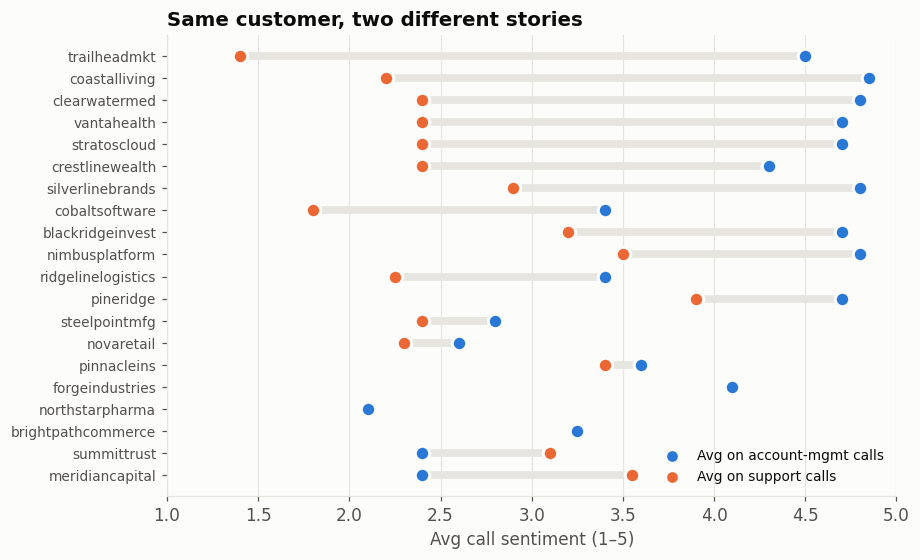

,account,n_calls,avg_external,avg_support,last_churn,competitors,journey
19,northstarpharma,2,2.10,2.10,high,"[CyberNova, SentinelShield]",Mar 12 ext 2.1 → Mar 15 sup 2.1
12,helixdata,1,2.30,NaN,high,[VaultEdge],Mar 17 ext 2.3
23,quantumedge,1,2.40,NaN,high,[SentinelShield],Mar 19 ext 2.4
28,stratoscloud,2,4.70,2.40,high,[],Mar 06 ext 4.7 → Apr 22 sup 2.4
29,summittrust,3,2.40,3.10,medium,[VaultEdge],Feb 06 sup 3.8 → Mar 26 ext 2.4 → Apr 15 sup 2.4
4,brightpathcommerce,4,3.25,3.25,high,[SentinelShield],Feb 11 ext 3.9 → Feb 21 sup 2.8 → Feb 27 sup 3.7 → Apr 22 ext 2.6
14,ironworkscorp,1,2.60,NaN,high,[Fortiguard Pro],Apr 14 ext 2.6
20,novaretail,2,2.60,2.30,high,[SentinelShield],Feb 14 sup 2.3 → Mar 21 ext 2.6
7,cobaltsoftware,2,3.40,1.80,medium,[SentinelShield],Mar 10 sup 1.8 → Apr 11 ext 3.4
17,meridiancapital,3,2.40,3.55,low,[SentinelShield],Mar 07 sup 3.7 → Mar 14 ext 2.4 → Mar 26 sup 3.4


In [20]:
health = insights.account_health(calls)
fig = viz.account_divergence(health); plt.show()
health[["account", "n_calls", "avg_external", "avg_support", "last_churn", "competitors", "journey"]].head(12)

For accounts with both kinds of calls, support calls average **~1.1 points lower** (20 accounts) than account-management calls. Several swings happen within days. Clearwater: 4.8 at kickoff → 2.4 three days later on a billing dispute. Crestline: 4.8 on Identity expansion → 2.4 three days later on a sync delay with a 5-day support wait. **Product idea:** an account health view that merges support and CS signals, and alerts the account owner when a support call goes negative near a renewal.

### 4e. Competitive intelligence

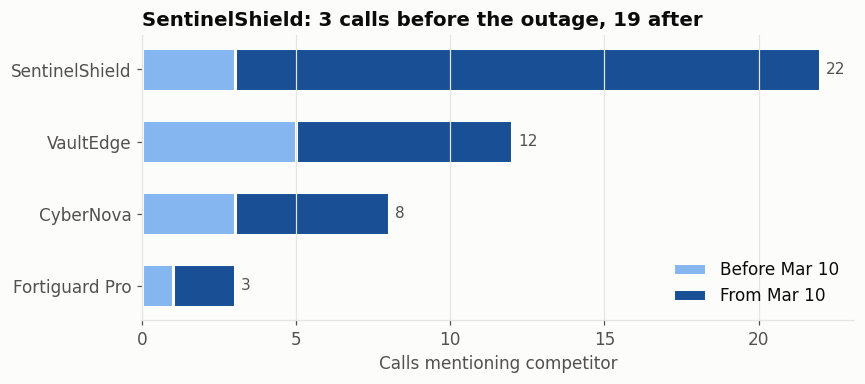

,calls,post_outage,raised_by_customer
competitor,,,
CyberNova,8,5,3
Fortiguard Pro,3,2,1
SentinelShield,22,19,13
VaultEdge,12,7,6


In [21]:
cm = insights.competitor_mentions(utts, calls)
fig = viz.competitor_chart(cm); plt.show()
cm.groupby("competitor").agg(calls=("meeting_id", "nunique"), post_outage=("post_outage", "sum"),
                             raised_by_customer=("said_by_customer", lambda s: (s > 0).sum()))

SentinelShield appears in 3 calls before the outage and **19 after**, and in 13 of the 22 calls the customer is the one who brings it up. It goes after Detect on reliability and SLA (offering a 99.9% SLA). VaultEdge comes up on Comply/Protect, CyberNova on Identity pricing. The internal win/loss call puts 5 lost deals down to the outage and $2.1M ACV lost in Q1 overall.

### 4f. Support quality — whose fault, and how it ends

In [22]:
pd.Series(insights.support_quality(calls)).astype(float).round(2)

,0
n_support_calls,30.00
aegis_root_cause_pct,0.70
customer_root_cause_pct,0.13
resolved_on_call_pct,0.17
escalated_pct,0.43
comm_gap_calls,10.00
support_delay_calls,5.00
known_issue_calls,4.00
avg_customer_net,-0.37
avg_aegis_net,0.01


In [23]:
sup = calls[calls.call_type == "support"]
pd.crosstab(sup.primary, sup.resolution)

resolution,escalated,feature_request_logged,info_provided,resolved_on_call,workaround_provided
primary,,,,,
BILLING,3,0,0,1,0
COMPLY,0,0,1,0,0
DEFECT,4,0,0,3,7
FEATURE,0,3,0,0,1
OUTAGE,6,0,0,1,0


* **70% of support calls have an Aegis-side root cause** and only 13% a customer-side one. Support here is mostly absorbing product and operations failures, not configuration questions.
* **4 cases were bugs Aegis already knew about** (backup agent 3.4.1, LogVault connector 3.4.1, Identity 3.4.1, Detect patch 4.2.1), and in **10 support calls** the customer complained that Aegis did not tell them first. A known-issue → affected-tenant notification would prevent a whole class of tickets.
* Only 17% resolve on the call and 43% escalate.

### 4g. Product backlog from the voice of the customer

In [24]:
insights.feature_backlog(calls)

,start,account,call_type,modules,churn_risk,rationale
6,2026-02-10 15:30:00+00:00,nimbusplatform,support,[Comply],low,Cross-framework control mapping report not supported; feature request escalated.
9,2026-02-13 11:00:00+00:00,bridgeporthealth,external,[Comply],low,HIPAA audit prep and multi-framework gaps in Comply.
17,2026-02-22 13:15:00+00:00,redwoodclinical,external,"[Protect, Comply, Identity]",medium,Four prioritised Comply reporting gaps; hints at VaultEdge evaluation.
29,2026-03-05 15:30:00+00:00,harborviewbank,external,[Detect],low,Post-go-live Detect tuning for alert fatigue.
31,2026-03-07 09:00:00+00:00,ridgelinelogistics,external,[Identity],medium,Identity session/MFA gaps; unanswered January ticket.
32,2026-03-07 13:30:00+00:00,meridiancapital,support,"[Comply, Identity]",low,Native SCIM not GA; REST API workaround.
56,2026-03-24 17:45:00+00:00,steelpointmfg,external,"[Detect, Protect, Comply]",medium,Contract review; exploratory CyberNova talks and CMMC gap.
57,2026-03-26 14:00:00+00:00,meridiancapital,support,[Protect],low,File-level restore missing in Protect.
65,2026-04-03 15:30:00+00:00,forgeindustries,support,[Comply],none,Question about Comply v2 early access and frameworks.
80,2026-04-16 13:00:00+00:00,pinnacleins,external,"[Detect, Comply]",low,Detect roadmap asks incl. pipeline health visibility.


## 5 · Limitations & next steps
* **n = 100, 12 weeks, one dominant event.** The trends describe this period and should not be read as general effects. Phase averages rest on 3–15 calls each.
* **LLM labels were produced once by one model.** Before production: double-label a 20% sample, measure agreement per field (churn risk is the most subjective), and version the prompt.
* Sentence sentiment comes from the source vendor and was validated against the call score, not against human labels.
* **Next:** embeddings for semantic search ("show me every call where a customer threatened to leave over SLA"), commitment tracking (did we send the post-mortem we promised?), and a revenue join (ARR per account) to rank risk in dollars.